Importing relevant libraries

In [33]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data Visualization

In [3]:
df = pd.read_csv("../data/processed/dataset_part_2.csv")
df.head()

   FlightNumber        Date BoosterVersion  PayloadMass Orbit    LaunchSite  \
0             1  2010-06-04       Falcon 9  6104.959412   LEO  CCAFS SLC 40   
1             2  2012-05-22       Falcon 9   525.000000   LEO  CCAFS SLC 40   
2             3  2013-03-01       Falcon 9   677.000000   ISS  CCAFS SLC 40   
3             4  2013-09-29       Falcon 9   500.000000    PO   VAFB SLC 4E   
4             5  2013-12-03       Falcon 9  3170.000000   GTO  CCAFS SLC 40   

       Outcome  Flights  GridFins  Reused   Legs LandingPad  Block  \
0    None None        1     False   False  False        NaN    1.0   
1    None None        1     False   False  False        NaN    1.0   
2    None None        1     False   False  False        NaN    1.0   
3  False Ocean        1     False   False  False        NaN    1.0   
4    None None        1     False   False  False        NaN    1.0   

   ReusedCount Serial   Longitude   Latitude  Class  
0            0  B0003  -80.577366  28.561857      

## Task 1 - Exploring relationship between Flight Number, Payload Mass and Launch Outcome

First, let's try to see how the `FlightNumber` (indicating the continuous launch attempts.) and `Payload` variables would affect the launch outcome.

We can plot out the `FlightNumber`vs. `PayloadMass` and overlay the outcome of the launch. 


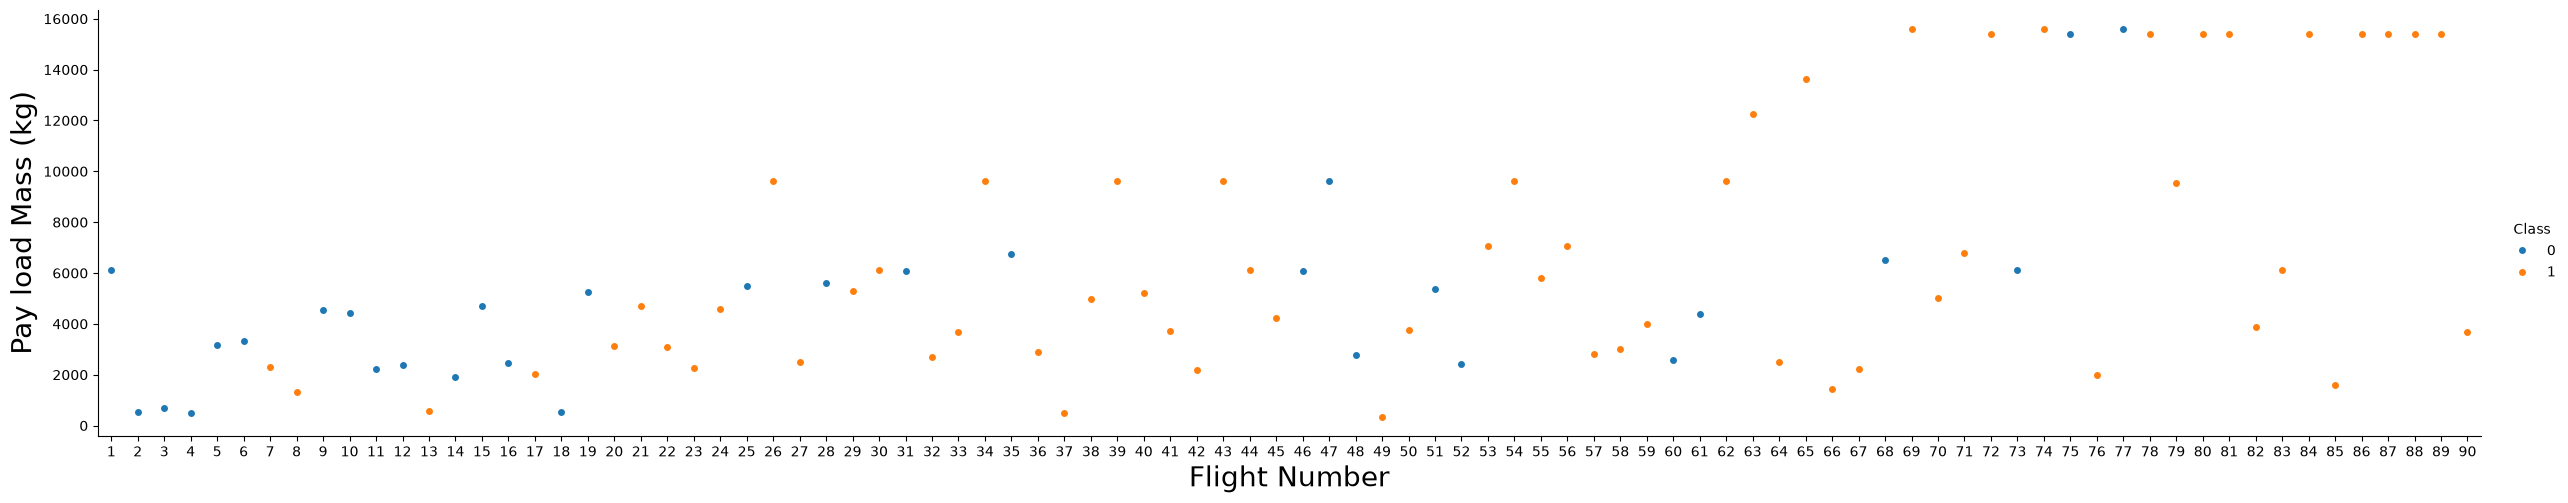

In [18]:
sns.catplot(data=df, x='FlightNumber', y = 'PayloadMass', hue='Class', aspect=5)
plt.xlabel("Flight Number",fontsize=20)
plt.ylabel("Pay load Mass (kg)",fontsize=20)
plt.show()

We see that as the flight number increases, the first stage is more likely to land successfully. The payload mass is also important; it seems the more massive the payload, the less likely the first stage will return.

## Task 2 - Visualizing the relationship between Flight Number, Launch Site and Launch Outcome

<Figure size 640x480 with 0 Axes>

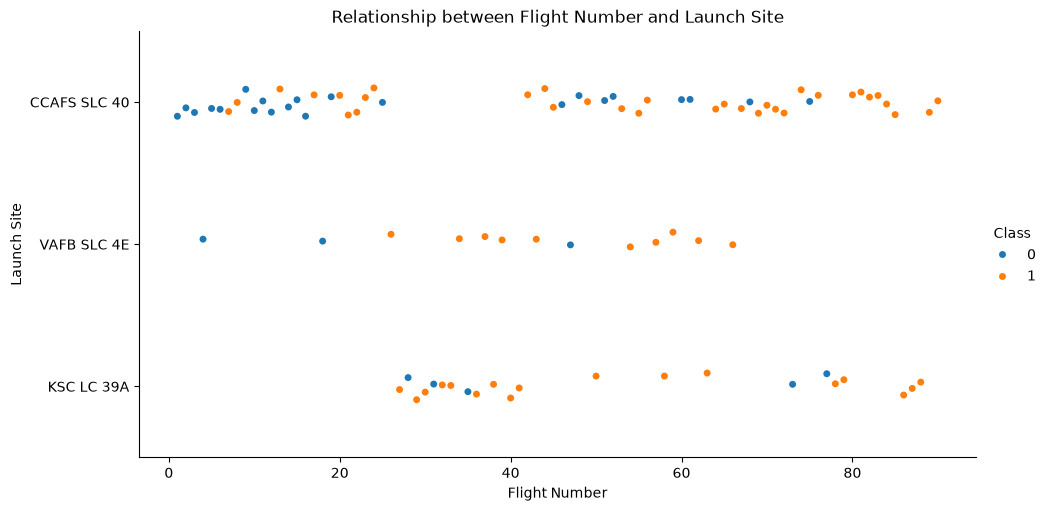

In [12]:
plt.figure()
sns.catplot(x=df.FlightNumber, y=df.LaunchSite, hue=df.Class, aspect=2)
plt.xlabel('Flight Number')
plt.ylabel('Launch Site')
plt.title('Relationship between Flight Number and Launch Site')
plt.show()

Observations ->
* **Evolution of Success Over Time:**
    * Earlier missions (Flight Numbers 1 to ~25) show a significant concentration of **Class 0** outcomes (blue dots), reflecting the experimental and learning phase of first-stage booster landings.
    *  Later missions (Flight Numbers > 40, and especially > 70) are overwhelmingly **Class 1** (orange dots), demonstrating dramatic improvements in landing reliability and booster reuse maturity.

* **Launch Site Timeline and Operational Patterns:**
    * **CCAFS SLC 40:** Serviced the earliest flights and handled the largest total volume. There is a visible gap in operations between roughly flight 25 and 40 (corresponding to pad repairs after the Amos-6 test anomaly), after which it resumed regular operations with high success rates.


    * **KSC LC 39A:** Only began hosting Falcon 9 launches later in the program (starting around flight 27–28). Because it came online after recovery techniques had matured, it exhibits the highest concentration of successful outcomes (almost entirely Class 1).


    * **VAFB SLC 4E:** Used less frequently for specialized polar orbit launches, with missions spread periodically across the timeline and maintaining a high overall success rate (only three Class 0 outcomes recorded).

## Task 3 - Visualizing the relationship between Payload and Launch Site

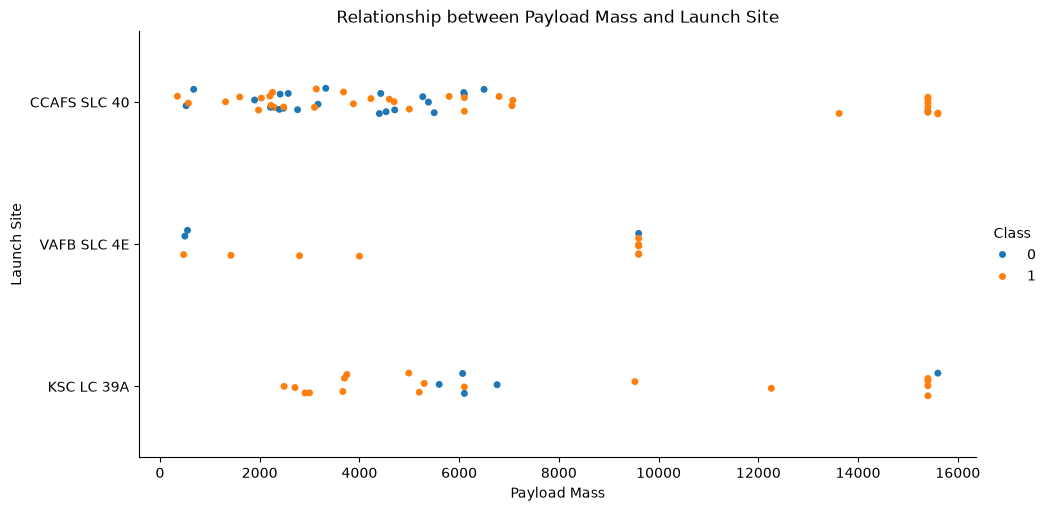

In [20]:
sns.catplot(x=df.PayloadMass, y=df.LaunchSite, hue=df.Class, aspect=2)
plt.xlabel('Payload Mass')
plt.ylabel('Launch Site')
plt.title('Relationship between Payload Mass and Launch Site')
plt.show()

Observations ->
* **Heavy Payloads (~15,600 kg):** Handled predominantly by **CCAFS SLC 40** and **KSC LC 39A**, with an almost perfect success rate (**Class 1**).
* **Mid-to-High Payloads (~9,600 kg):** Consistently launched from **VAFB SLC 4E** (with one flight from KSC LC 39A), showing strong success rates.
* **Light to Moderate Payloads (< 7,000 kg):** Distributed widely across all three sites, exhibiting a mix of successes and failures (**Class 0**), particularly at **CCAFS SLC 40** where most earlier missions occurred.

## Task 4: Visualizing the relationship between success rate of each orbit type


In [21]:
orbit_success = df.groupby('Orbit')['Class'].mean().reset_index()
orbit_success = orbit_success.sort_values('Class', ascending=False)
orbit_success = orbit_success[orbit_success['Orbit'] != 'SO']
orbit_success

    Orbit     Class
0   ES-L1  1.000000
1     GEO  1.000000
3     HEO  1.000000
9     SSO  1.000000
10   VLEO  0.857143
5     LEO  0.714286
7      PO  0.666667
6     MEO  0.666667
4     ISS  0.619048
2     GTO  0.518519

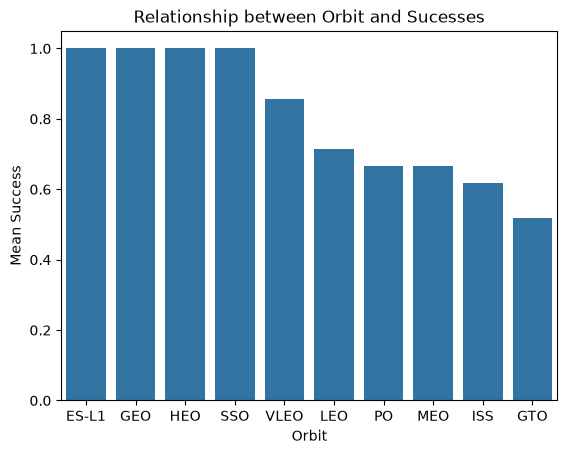

In [26]:
plt.figure()
sns.barplot(data=orbit_success, x='Orbit', y='Class')
plt.xlabel('Orbit')
plt.ylabel('Mean Success')
plt.title('Relationship between Orbit and Sucesses')
plt.show()

- Also, analyzing how many vehicles launched for each orbit type

<Axes: xlabel='Orbit', ylabel='count'>

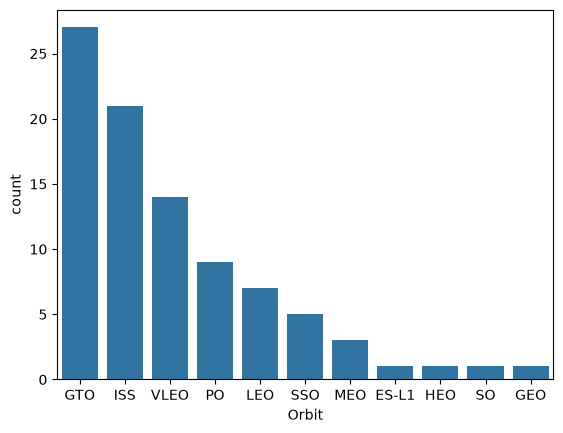

In [23]:
sns.barplot(df.value_counts('Orbit'))

Observations ->
* **Sample Size Disparity:** The orbits with perfect 100% success rates (**ES-L1**, **GEO**, **HEO**) have only 1 recorded launch each, and **SSO** has just 5, meaning their high rates reflect small sample sizes rather than inherent reliability.
* **High-Volume Orbit Outcomes:** **GTO** and **ISS** account for the largest share of missions (27 and 21 launches respectively), but show lower success rates (~52% and ~62%) because many of these took place during earlier development phases.
* **High Success in Moderate Volume:** **VLEO** stands out with both substantial flight volume (14 launches) and a high landing success rate (~85%).

## Task 5 - Visualizing the relationship between Flight Number and Orbit type

Text(0.5, 1.0, 'Relationship between Flight Number and Orbit type')

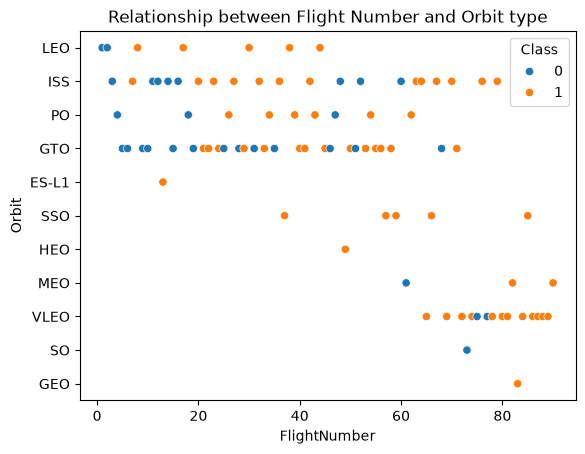

In [ ]:
sns.scatterplot(x=df.FlightNumber, y=df.Orbit, hue=df.Class)
plt.title('Relationship between Flight Number and Orbit type')

Observations ->
* **Transition Over Time:** Early missions (Flight Numbers < 40) predominantly targeted **ISS**, **GTO**, and **LEO**, where failed landings (**Class 0**) were frequent.
* **Emergence of VLEO:** **VLEO** missions appear exclusively in the later operational phase (Flight Numbers > 60) and demonstrate an almost perfect landing success rate (**Class 1**).
* **Longitudinal Improvement:** Later flights across recurring orbits like **ISS** and **GTO** shift markedly from mixed/failed outcomes to consistent successes as booster recovery matured.

## Task 6 - Visualizing relationship between Payload and Orbit type

Text(0.5, 1.0, 'Relationship between Payload and Orbit Type')

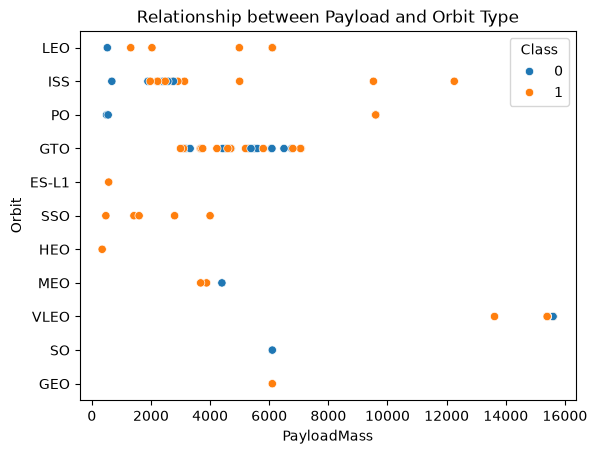

In [29]:
sns.scatterplot(x=df.PayloadMass, y=df.Orbit, hue=df.Class)
plt.title('Relationship between Payload and Orbit Type')

## Task 7 - Visualizing the yearly launch success trend

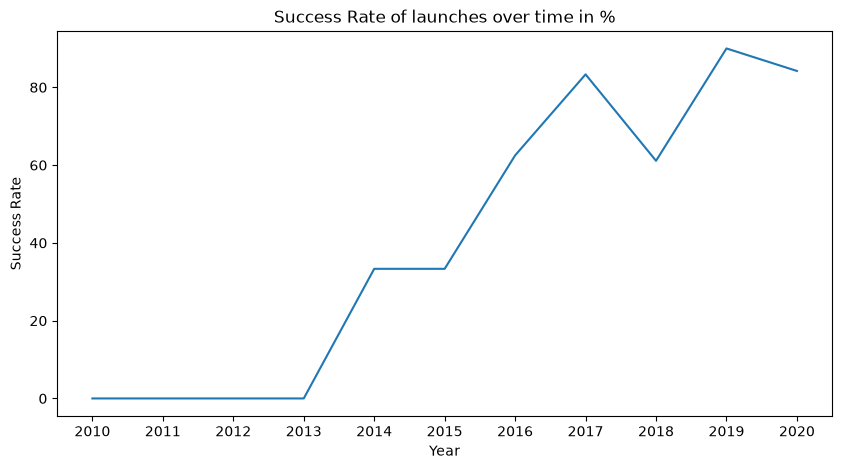

In [27]:
df['Year'] = [int(date.split('-')[0]) for date in df['Date']]
success_v_year = df.groupby('Year')['Class'].mean().reset_index()
success_v_year["Success_Rate"] = [(Class*100) for Class in success_v_year.Class]

plt.figure(figsize=(10,5))
sns.lineplot(x=success_v_year.Year, y=success_v_year.Success_Rate)
plt.xlabel('Year')
plt.ylabel('Success Rate')
plt.title('Success Rate of launches over time in %')
plt.xticks(np.arange(success_v_year.Year.min(), success_v_year.Year.max() +1, 1))
plt.show()

Observations ->
* **Early Baseline (2010–2013):** The success rate remained at 0% during the initial developmental and experimental phase.
* **Rapid Growth (2013–2017):** Success climbed sharply from 0% in 2013 to over 80% in 2017 as recovery systems matured.
* **Temporary Dip (2018):** Success dropped to ~61% before rebounding sharply.
* **High-Reliability Plateau (2019–2020):** Success peaked near 90% in 2019 and remained high at ~84% in 2020, demonstrating established operational consistency.

_____________________________________________________________________

# Feature Engineering

In [28]:
# Feature Selection
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features.head()

   FlightNumber  PayloadMass Orbit    LaunchSite  Flights  GridFins  Reused  \
0             1  6104.959412   LEO  CCAFS SLC 40        1     False   False   
1             2   525.000000   LEO  CCAFS SLC 40        1     False   False   
2             3   677.000000   ISS  CCAFS SLC 40        1     False   False   
3             4   500.000000    PO   VAFB SLC 4E        1     False   False   
4             5  3170.000000   GTO  CCAFS SLC 40        1     False   False   

    Legs LandingPad  Block  ReusedCount Serial  
0  False        NaN    1.0            0  B0003  
1  False        NaN    1.0            0  B0005  
2  False        NaN    1.0            0  B0007  
3  False        NaN    1.0            0  B1003  
4  False        NaN    1.0            0  B1004  

## Task 8 - Creating dummy variables to categorical columns

In [30]:
cat_features = ['Orbit', 'LaunchSite', 'LandingPad', 'Serial']
features_one_hot = pd.get_dummies(features, columns=cat_features)
features_one_hot.head()

   FlightNumber  PayloadMass  Flights  GridFins  Reused   Legs  Block  \
0             1  6104.959412        1     False   False  False    1.0   
1             2   525.000000        1     False   False  False    1.0   
2             3   677.000000        1     False   False  False    1.0   
3             4   500.000000        1     False   False  False    1.0   
4             5  3170.000000        1     False   False  False    1.0   

   ReusedCount  Orbit_ES-L1  Orbit_GEO  ...  Serial_B1048  Serial_B1049  \
0            0        False      False  ...         False         False   
1            0        False      False  ...         False         False   
2            0        False      False  ...         False         False   
3            0        False      False  ...         False         False   
4            0        False      False  ...         False         False   

   Serial_B1050  Serial_B1051  Serial_B1054  Serial_B1056  Serial_B1058  \
0         False         False      

## Task 9 - Casting all numeric columns to `float64`

In [32]:
features_one_hot = features_one_hot.astype('float64')
print(features_one_hot.dtypes)
features_one_hot.head()

FlightNumber    float64
PayloadMass     float64
Flights         float64
GridFins        float64
Reused          float64
                 ...   
Serial_B1056    float64
Serial_B1058    float64
Serial_B1059    float64
Serial_B1060    float64
Serial_B1062    float64
Length: 80, dtype: object


   FlightNumber  PayloadMass  Flights  GridFins  Reused  Legs  Block  \
0           1.0  6104.959412      1.0       0.0     0.0   0.0    1.0   
1           2.0   525.000000      1.0       0.0     0.0   0.0    1.0   
2           3.0   677.000000      1.0       0.0     0.0   0.0    1.0   
3           4.0   500.000000      1.0       0.0     0.0   0.0    1.0   
4           5.0  3170.000000      1.0       0.0     0.0   0.0    1.0   

   ReusedCount  Orbit_ES-L1  Orbit_GEO  ...  Serial_B1048  Serial_B1049  \
0          0.0          0.0        0.0  ...           0.0           0.0   
1          0.0          0.0        0.0  ...           0.0           0.0   
2          0.0          0.0        0.0  ...           0.0           0.0   
3          0.0          0.0        0.0  ...           0.0           0.0   
4          0.0          0.0        0.0  ...           0.0           0.0   

   Serial_B1050  Serial_B1051  Serial_B1054  Serial_B1056  Serial_B1058  \
0           0.0           0.0           0

In [34]:
if os.path.exists('../data/processed/dataset_part_3.csv'):
    print('File exists...')
else:
    features_one_hot.to_csv('../data/processed/dataset_part_3.csv', index=False)

File exists...
